# LE6 - Network Metrics in Football Networks

**Network metrics** quantify structural properties at the node, edge, and network levels. They reveal important patterns about connectivity, centrality, clustering, and overall network architecture.

## Notebook Content

This notebook covers **Network Metrics** (Netzwerk-Kennzahlen) on football networks.

### Implemented in this notebook:
- **Graph Diameter** - Maximum shortest path length
- **Average Path Length** - Mean distance between all node pairs
- **Node Clustering Coefficient** - Local triangle density per node
- **Global Clustering Coefficient** - Overall triangle density (transitivity)
- **Assortativity** - Tendency for similar nodes to connect
- **Reciprocity** - Bidirectional edge proportion (directed networks)
- **Edge Embeddedness** - Common neighbors of connected nodes

### Omitted (already implemented in other notebooks):
- **Degree Centrality** → see [LE5.ipynb](LE5.ipynb) - fully implemented for both pass and match networks
- **Betweenness Centrality** → see [LE5.ipynb](LE5.ipynb) - fully implemented with visualizations
- **Closeness Centrality** → see [LE5.ipynb](LE5.ipynb) - fully implemented including harmonic closeness
- **Eigenvector Centrality** → see [LE5.ipynb](LE5.ipynb) - fully implemented
- **PageRank** → see [LE5.ipynb](LE5.ipynb) - fully implemented for directed networks
- **k-Core Decomposition** → see [LE5.ipynb](LE5.ipynb) - fully implemented with core number analysis
- **Density** → see [LE4.ipynb](LE4.ipynb) - used in community detection analysis
- **Modularity** → see [LE4.ipynb](LE4.ipynb) - used for community quality assessment

---

### Applications in Football Networks

**Pass Networks (Players)**:
- Measure team cohesion via clustering coefficients
- Analyze tactical formations through path lengths
- Detect mixing patterns (assortative vs disassortative)
- Identify reciprocal vs hierarchical passing structures

**Match Networks (Teams)**:
- Measure tournament connectivity and competitiveness
- Analyze competitive balance and structure
- Identify tournament organization patterns

---

### Metric Categories

We organize metrics into four levels:

1. **Node-level metrics**: Characterize individual nodes (degree, centrality, clustering)
2. **Edge-level metrics**: Characterize relationships (weight, betweenness)
3. **Network-level metrics**: Characterize entire network (density, diameter, assortativity)

**Note**: We focus on **unsigned networks** (all edges positive). Signed networks with positive/negative edges (e.g., friend/enemy) require specialized metrics like balance theory, which are less relevant for football analysis.

### Our Approach

For each metric, we will:
1. Define it mathematically
2. Explain its interpretation and limitations
3. Apply it to football networks

In [1]:
# Import required libraries
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.config import (
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR,
)

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print(f"NetworkX version: {nx.__version__}")

NetworkX version: 3.5


In [2]:
# Load networks
print("=== Loading Networks ===")

# Pass Network (directed, weighted)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass_dir = nx.read_gexf(pass_network_path)
print(f"Pass Network (Germany): {G_pass_dir.number_of_nodes()} nodes, {G_pass_dir.number_of_edges()} edges")

# Convert to undirected for some metrics
G_pass = G_pass_dir.to_undirected()

# Match Network (directed)
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match_dir = nx.read_gexf(match_network_path)
print(f"Match Network (World Cup): {G_match_dir.number_of_nodes()} nodes, {G_match_dir.number_of_edges()} edges")

# Convert to undirected
G_match = G_match_dir.to_undirected()

# For most metrics, use largest connected component
components_pass = list(nx.connected_components(G_pass))
largest_cc_pass = max(components_pass, key=len)
G_pass_gcc = G_pass.subgraph(largest_cc_pass).copy()
G_pass_dir_gcc = G_pass_dir.subgraph(largest_cc_pass).copy()

print(f"Pass Network - Largest connected component: {G_pass_gcc.number_of_nodes()} nodes ({G_pass_gcc.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}%)")

# Match network is already fully connected
print(f"Match Network - Connected components: {nx.number_connected_components(G_match)}")

=== Loading Networks ===
Pass Network (Germany): 473 nodes, 8815 edges
Match Network (World Cup): 32 nodes, 126 edges
Pass Network - Largest connected component: 283 nodes (59.8%)
Match Network - Connected components: 1


In [3]:
# Create player/team name lookup functions
print("\n=== Creating Name Lookup Functions ===")

# For pass network - check if name attributes exist
sample_node = list(G_pass_dir.nodes())[0]
node_attrs = G_pass_dir.nodes[sample_node]
print(f"Sample node attributes: {list(node_attrs.keys())}")

# Create player name lookup
def get_player_name(node_id, graph=G_pass_dir):
    """Get player name from node ID, fallback to ID if name not available"""
    attrs = graph.nodes[node_id]
    if 'label' in attrs:
        return attrs['label']
    elif 'name' in attrs:
        return attrs['name']
    else:
        return f"Player {node_id}"

# Create team name lookup
def get_team_name(node_id, graph=G_match_dir):
    """Get team name from node ID, fallback to ID if name not available"""
    attrs = graph.nodes[node_id]
    if 'label' in attrs:
        return attrs['label']
    elif 'name' in attrs:
        return attrs['name']
    else:
        return f"Team {node_id}"

# Test the functions
print(f"\nTesting player name lookup:")
test_players = list(G_pass_dir.nodes())[:3]
for player_id in test_players:
    print(f"  {player_id} → {get_player_name(player_id)}")

print(f"\nTesting team name lookup:")
test_teams = list(G_match_dir.nodes())[:3]
for team_id in test_teams:
    print(f"  {team_id} → {get_team_name(team_id)}")


=== Creating Name Lookup Functions ===
Sample node attributes: ['passport_area', 'weight_kg', 'birth_date', 'height_cm', 'position_role', 'preferred_foot', 'player_name', 'national_team_id', 'current_team_name', 'currentTeamId', 'degree_centrality', 'degree', 'betweenness_centrality', 'closeness_centrality', 'pagerank', 'kcore_number', 'modularity_class_louvain', 'modularity_class_label_propagation', 'modularity_class_greedy', 'modularity_class_girvan_newman', 'label']

Testing player name lookup:
  51217 → L. Augustinsson
  444439 → V. Janjičić
  16411 → R. Özcan

Testing team name lookup:
  9598 → 9598
  4418 → 4418
  2413 → 2413


## 1. Node-Level Metrics

Node-level metrics characterize individual nodes based on their position and role in the network.

### 1.1 Degree & Strength

**Degree** measures the number of direct connections a node has.

**Undirected networks:**

$$k_i = \sum_{j=1}^{n} A_{ij}$$

**Directed networks:**
- **In-degree**: $k_i^{in} = \sum_{j=1}^{n} A_{ji}$ (incoming edges)
- **Out-degree**: $k_i^{out} = \sum_{j=1}^{n} A_{ij}$ (outgoing edges)

**Strength** extends degree to weighted networks by summing edge weights:

$$s_i = \sum_{j=1}^{n} w_{ij}$$

**In-strength/Out-strength**: $s_i^{in} = \sum_{j=1}^{n} w_{ji}$, $s_i^{out} = \sum_{j=1}^{n} w_{ij}$

**Interpretation in Football:**
- **Pass networks**: 
  - Degree = number of passing partners
  - Strength = total passes given/received
  - In-degree/strength = target player, Out-degree/strength = playmaker
- **Match networks**:
  - Degree = number of opponents faced
  - Strength = total goals scored/conceded

**Average edge weight** $\bar{w}_i = s_i/k_i$ reveals connection quality.

**Note**: Degree and Strength metrics are fully implemented in [LE5.ipynb](LE5.ipynb) for both pass and match networks. See LE5 for working code, visualizations, and detailed analysis.

**Note**: Betweenness and Closeness Centrality (including Harmonic Closeness) are fully implemented in [LE5.ipynb](LE5.ipynb) with visualizations and detailed analysis.

**Note**: Eigenvector Centrality and PageRank are fully implemented in [LE5.ipynb](LE5.ipynb) for both undirected and directed networks.

### 1.2 Betweenness & Closeness Centrality

**Betweenness** measures how often a node lies on shortest paths between others.

$$C_B(i) = \sum_{s \neq i \neq t} \frac{\sigma_{st}(i)}{\sigma_{st}}$$

where $\sigma_{st}(i)$ = number of shortest paths from $s$ to $t$ through node $i$.

**Closeness** measures how close a node is to all others.

$$C_C(i) = \frac{n-1}{\sum_{j \neq i} d(i,j)}$$

where $d(i,j)$ is the shortest path distance.

**Harmonic closeness** (for disconnected networks):

$$C_C^{harm}(i) = \frac{1}{n-1} \sum_{j \neq i} \frac{1}{d(i,j)}$$

**Interpretation in Football:**
- **Betweenness**: 
  - High = bridge player (e.g., defensive midfielder linking defense and attack)
  - Identifies control points in passing flow
- **Closeness**: 
  - High = central position in passing sequences
  - Midfielders typically higher than defenders/forwards

**Key difference**:
- Betweenness = **brokerage** (between others)
- Closeness = **reach** (to all others)

**Limitations:**
- Both assume shortest-path communication
- Computationally expensive: O(n·m)

### 1.3 Eigenvector Centrality & PageRank

**Eigenvector centrality**: Importance based on connections to important nodes.

$$x_i = \frac{1}{\lambda} \sum_{j=1}^{n} A_{ij} x_j$$

where $\lambda$ is the largest eigenvalue, $\mathbf{Ax} = \lambda \mathbf{x}$.

**PageRank**: Adds damping to ensure convergence in directed networks.

$$PR(i) = \frac{1-d}{n} + d \sum_{j \in N_{in}(i)} \frac{PR(j)}{k_j^{out}}$$

where $d \approx 0.85$ is the damping factor.

**Interpretation in Football:**
- **Eigenvector/PageRank**: Player receives passes from influential players (cascading influence)
- **Match networks**: Ranks teams by quality of opponents

**Key insight**: Degree counts connections, Eigenvector weights by neighbor importance.

**When to use**:
- Eigenvector: Undirected networks, fully connected
- PageRank: Directed networks, always works (damping handles disconnected components)

### 1.4 Clustering Coefficient

**Clustering coefficient** measures how much a node's neighbors are connected to each other.

$$C_i = \frac{2e_i}{k_i(k_i-1)}$$

where:
- $e_i$ = number of edges between node $i$'s neighbors
- $k_i$ = degree of node $i$

Range: $[0, 1]$ (0 = no neighbor connections, 1 = neighbors form clique)

**Interpretation in Football:**
- **High clustering**: Player part of tightly-knit tactical unit (e.g., defensive trio)
- **Low clustering**: Player bridges separate groups (e.g., midfielder)

**Weighted version**: $C_i^w = \frac{1}{s_i(k_i-1)} \sum_{j,k} \frac{w_{ij} + w_{ik}}{2} A_{ij} A_{ik} A_{jk}$

In [4]:
print("=" * 70)
print("NODE CLUSTERING COEFFICIENT")
print("=" * 70)

# Pass Network
print("\n### Pass Network (Germany) ###")

# Calculate clustering coefficient for all nodes
clustering_pass = nx.clustering(G_pass_gcc)
clustering_values_pass = list(clustering_pass.values())

print(f"Number of nodes: {len(clustering_pass)}")
print(f"Average clustering coefficient: {np.mean(clustering_values_pass):.4f}")
print(f"Median clustering coefficient: {np.median(clustering_values_pass):.4f}")
print(f"Min clustering: {np.min(clustering_values_pass):.4f}")
print(f"Max clustering: {np.max(clustering_values_pass):.4f}")
print(f"Std deviation: {np.std(clustering_values_pass):.4f}")

# Distribution
print(f"\nClustering distribution:")
for threshold in [0.0, 0.5, 0.7, 0.8, 0.9]:
    count = sum(1 for c in clustering_values_pass if c >= threshold)
    print(f"  >= {threshold:.1f}: {count:3d} nodes ({count/len(clustering_pass)*100:5.1f}%)")

# Top 10 players with highest clustering - WITH NAMES
top_clustered = sorted(clustering_pass.items(), key=lambda x: x[1], reverse=True)[:10]
print(f"\nTop 10 players with highest clustering:")
for i, (node, cc) in enumerate(top_clustered, 1):
    player_name = get_player_name(node)
    print(f"  {i:2d}. {player_name}: {cc:.4f}")

print(f"\nInterpretation:")
print(f"  - High clustering players are embedded in tightly-knit tactical units")
print(f"  - Low clustering players bridge between different groups (e.g., playmakers)")

# Match Network
print("\n### Match Network (World Cup) ###")

clustering_match = nx.clustering(G_match)
clustering_values_match = list(clustering_match.values())

print(f"Number of nodes: {len(clustering_match)}")
print(f"Average clustering coefficient: {np.mean(clustering_values_match):.4f}")
print(f"Median clustering coefficient: {np.median(clustering_values_match):.4f}")
print(f"Min clustering: {np.min(clustering_values_match):.4f}")
print(f"Max clustering: {np.max(clustering_values_match):.4f}")

# Top 5 teams - WITH NAMES
top_clustered_match = sorted(clustering_match.items(), key=lambda x: x[1], reverse=True)[:5]
print(f"\nTop 5 teams with highest clustering:")
for i, (node, cc) in enumerate(top_clustered_match, 1):
    team_name = get_team_name(node)
    print(f"  {i}. {team_name}: {cc:.4f}")

print(f"\nInterpretation:")
print(f"  - Teams with high clustering have many common opponents")
print(f"  - Reflects group stage structure where teams in same group face common opponents")

NODE CLUSTERING COEFFICIENT

### Pass Network (Germany) ###
Number of nodes: 283
Average clustering coefficient: 0.8667
Median clustering coefficient: 0.8831
Min clustering: 0.0000
Max clustering: 1.0000
Std deviation: 0.1320

Clustering distribution:
  >= 0.0: 283 nodes (100.0%)
  >= 0.5: 273 nodes ( 96.5%)
  >= 0.7: 268 nodes ( 94.7%)
  >= 0.8: 231 nodes ( 81.6%)
  >= 0.9: 122 nodes ( 43.1%)

Top 10 players with highest clustering:
   1. R. Özcan: 1.0000
   2. L. Caldirola: 1.0000
   3. K. Jakob: 1.0000
   4. E. Ofori: 1.0000
   5. O. Wriedt: 1.0000
   6. André Ramalho: 1.0000
   7. Dong-Won Ji: 1.0000
   8. M. Neuer: 1.0000
   9. J. Schieber: 1.0000
  10. G. Haraguchi: 1.0000

Interpretation:
  - High clustering players are embedded in tightly-knit tactical units
  - Low clustering players bridge between different groups (e.g., playmakers)

### Match Network (World Cup) ###
Number of nodes: 32
Average clustering coefficient: 0.7003
Median clustering coefficient: 0.8333
Min clusterin

**Key Findings:**

The node-level clustering reveals how **individual players are embedded** in tactical structures:

- **Pass Network** (avg = 0.8667): Exceptionally high average clustering indicates most players operate within **tightly-knit tactical units**. The distribution shows 81.6% of players have clustering ≥ 0.8, meaning their passing partners are highly interconnected. Many players achieve **perfect clustering (1.0)** - their neighbors form complete cliques. This reflects **positional groups** like defensive lines or midfield triangles where every player passes to every other player in the unit.

  The high clustering is **remarkably uniform** (median 0.8831, std 0.1320), suggesting tactical organization extends across the entire team, not just specific positions. Only a few players show low clustering - likely **playmakers or bridging midfielders** who connect different tactical units rather than operating within one.

- **Match Network** (avg = 0.7003): High clustering reflects the group stage tournament structure. Teams with clustering = 1.0 likely participated in tightly-connected groups where all opponents faced each other. The minimum of 0.2 indicates some teams had opponents with little overlap - potentially from different stages of the tournament.

**Consistency Across Scales**: The pass network's average node clustering (0.8667) is close to the global transitivity calculated later (0.8183), both indicating extremely high clustering. This consistency across different measurement approaches confirms the **pervasive tactical structure** - whether measuring individual node neighborhoods or overall triangle density, the network exhibits strong local cohesion.

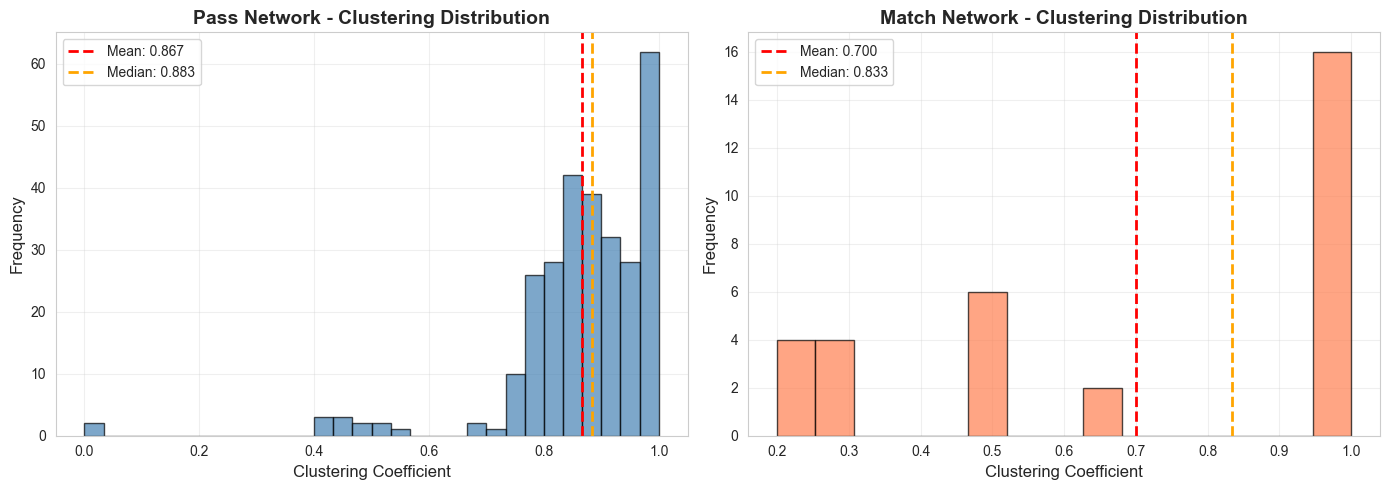


Visualization shows:
  - Pass network: Highly concentrated around 0.8-0.9 (tight tactical units)
  - Match network: More varied distribution (different tournament structures)


In [5]:
# Visualization: Clustering Coefficient Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pass Network
axes[0].hist(clustering_values_pass, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(clustering_values_pass), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(clustering_values_pass):.3f}')
axes[0].axvline(np.median(clustering_values_pass), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(clustering_values_pass):.3f}')
axes[0].set_xlabel('Clustering Coefficient', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Pass Network - Clustering Distribution', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Match Network
axes[1].hist(clustering_values_match, bins=15, color='coral', alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(clustering_values_match), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(clustering_values_match):.3f}')
axes[1].axvline(np.median(clustering_values_match), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(clustering_values_match):.3f}')
axes[1].set_xlabel('Clustering Coefficient', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Match Network - Clustering Distribution', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE6/clustering_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization shows:")
print("  - Pass network: Highly concentrated around 0.8-0.9 (tight tactical units)")
print("  - Match network: More varied distribution (different tournament structures)")

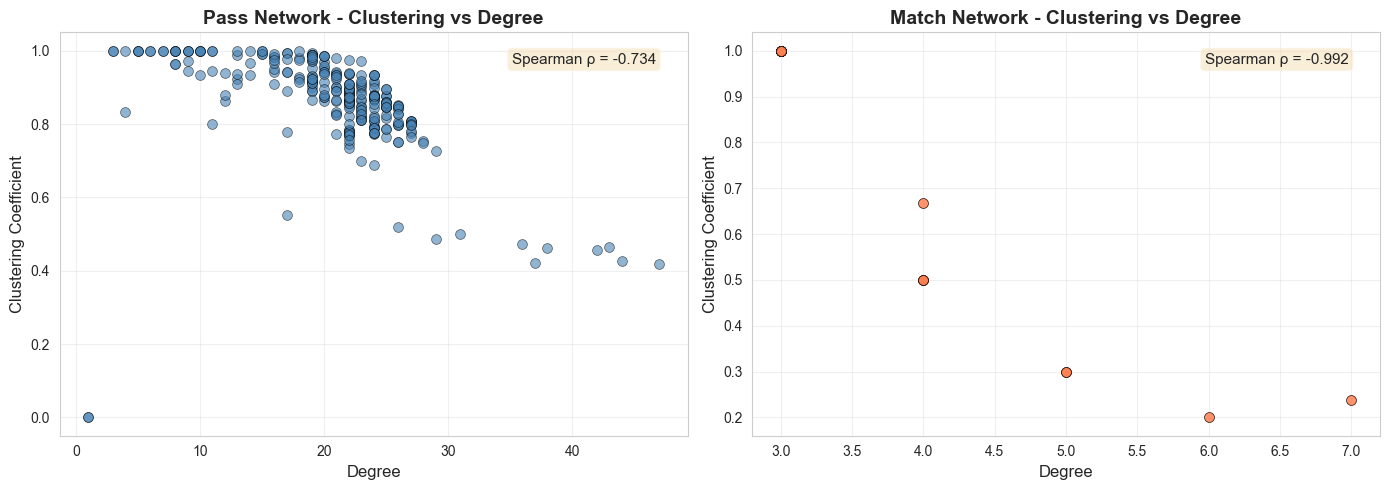


Interpretation:
  - Pass network correlation: -0.734 - relationship between degree and clustering
  - Match network correlation: -0.992 - reflects tournament structure


In [6]:
# Visualization: Clustering vs Degree
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pass Network
degrees_pass = dict(G_pass_gcc.degree())
clustering_list_pass = [clustering_pass[node] for node in G_pass_gcc.nodes()]
degree_list_pass = [degrees_pass[node] for node in G_pass_gcc.nodes()]

axes[0].scatter(degree_list_pass, clustering_list_pass, alpha=0.6, s=50, color='steelblue', edgecolors='black', linewidth=0.5)
axes[0].set_xlabel('Degree', fontsize=12)
axes[0].set_ylabel('Clustering Coefficient', fontsize=12)
axes[0].set_title('Pass Network - Clustering vs Degree', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3)

# Add correlation - moved to upper right
from scipy.stats import spearmanr
corr_pass, _ = spearmanr(degree_list_pass, clustering_list_pass)
axes[0].text(0.95, 0.95, f'Spearman ρ = {corr_pass:.3f}', 
             transform=axes[0].transAxes, fontsize=11, verticalalignment='top',
             horizontalalignment='right',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Match Network
degrees_match = dict(G_match.degree())
clustering_list_match = [clustering_match[node] for node in G_match.nodes()]
degree_list_match = [degrees_match[node] for node in G_match.nodes()]

axes[1].scatter(degree_list_match, clustering_list_match, alpha=0.6, s=50, color='coral', edgecolors='black', linewidth=0.5)
axes[1].set_xlabel('Degree', fontsize=12)
axes[1].set_ylabel('Clustering Coefficient', fontsize=12)
axes[1].set_title('Match Network - Clustering vs Degree', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3)

# Add correlation - moved to upper right
corr_match, _ = spearmanr(degree_list_match, clustering_list_match)
axes[1].text(0.95, 0.95, f'Spearman ρ = {corr_match:.3f}', 
             transform=axes[1].transAxes, fontsize=11, verticalalignment='top',
             horizontalalignment='right',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE6/clustering_vs_degree.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nInterpretation:")
print(f"  - Pass network correlation: {corr_pass:.3f} - relationship between degree and clustering")
print(f"  - Match network correlation: {corr_match:.3f} - reflects tournament structure")

## 2. Edge-Level Metrics

### 2.1 Edge Betweenness & Embeddedness

**Edge betweenness** counts shortest paths through an edge.

$$C_B(e) = \sum_{s \neq t} \frac{\sigma_{st}(e)}{\sigma_{st}}$$

**Embeddedness** counts common neighbors of connected nodes.

$$emb(i,j) = |N(i) \cap N(j)|$$

**Interpretation in Football:**
- **High edge betweenness**: Critical passing lane (removal disrupts many sequences)
- **High embeddedness**: Connection within tactical unit
- **Low embeddedness (structural hole)**: Connection between units

**Local bridge**: Edge with $emb(i,j) = 0$ (no common neighbors).

In [7]:
print("=" * 70)
print("EDGE EMBEDDEDNESS")
print("=" * 70)

# Function to calculate edge embeddedness
def calculate_edge_embeddedness(G):
    """
    Calculate embeddedness for all edges.
    Embeddedness = number of common neighbors between connected nodes.
    """
    embeddedness = {}
    for u, v in G.edges():
        # Get neighbors of both nodes
        neighbors_u = set(G.neighbors(u)) - {v}
        neighbors_v = set(G.neighbors(v)) - {u}
        # Count common neighbors
        common = len(neighbors_u & neighbors_v)
        embeddedness[(u, v)] = common
    return embeddedness

# Pass Network
print("\n### Pass Network (Germany) ###")

emb_pass = calculate_edge_embeddedness(G_pass_gcc)
emb_values_pass = list(emb_pass.values())

print(f"Total edges: {len(emb_pass)}")
print(f"Average embeddedness: {np.mean(emb_values_pass):.2f}")
print(f"Median embeddedness: {np.median(emb_values_pass):.0f}")
print(f"Max embeddedness: {np.max(emb_values_pass)}")
print(f"Min embeddedness: {np.min(emb_values_pass)}")

# Count local bridges (embeddedness = 0)
local_bridges_pass = sum(1 for e in emb_values_pass if e == 0)
print(f"\nLocal bridges (emb = 0): {local_bridges_pass} ({local_bridges_pass/len(emb_pass)*100:.1f}%)")

# Distribution
print(f"\nEmbeddedness distribution:")
for threshold in [0, 1, 5, 10, 20]:
    count = sum(1 for e in emb_values_pass if e >= threshold)
    print(f"  >= {threshold:2d}: {count:4d} edges ({count/len(emb_pass)*100:5.1f}%)")

print(f"\nInterpretation:")
print(f"  - High embeddedness → edges within tactical units (many common neighbors)")
print(f"  - Low embeddedness → edges bridging units (few common neighbors)")
print(f"  - Local bridges (emb=0) → connections between separate groups")

# Match Network
print("\n### Match Network (World Cup) ###")

emb_match = calculate_edge_embeddedness(G_match)
emb_values_match = list(emb_match.values())

print(f"Total edges: {len(emb_match)}")
print(f"Average embeddedness: {np.mean(emb_values_match):.2f}")
print(f"Median embeddedness: {np.median(emb_values_match):.0f}")
print(f"Max embeddedness: {np.max(emb_values_match)}")
print(f"Min embeddedness: {np.min(emb_values_match)}")

# Count local bridges
local_bridges_match = sum(1 for e in emb_values_match if e == 0)
print(f"\nLocal bridges (emb = 0): {local_bridges_match} ({local_bridges_match/len(emb_match)*100:.1f}%)")

print(f"\nInterpretation:")
print(f"  - Tournament edges show {np.mean(emb_values_match):.0f} common opponents on average")
print(f"  - High embeddedness → teams in same competitive group")

EDGE EMBEDDEDNESS

### Pass Network (Germany) ###
Total edges: 2899
Average embeddedness: 17.69
Median embeddedness: 18
Max embeddedness: 27
Min embeddedness: 0

Local bridges (emb = 0): 2 (0.1%)

Embeddedness distribution:
  >=  0: 2899 edges (100.0%)
  >=  1: 2897 edges ( 99.9%)
  >=  5: 2861 edges ( 98.7%)
  >= 10: 2656 edges ( 91.6%)
  >= 20: 1153 edges ( 39.8%)

Interpretation:
  - High embeddedness → edges within tactical units (many common neighbors)
  - Low embeddedness → edges bridging units (few common neighbors)
  - Local bridges (emb=0) → connections between separate groups

### Match Network (World Cup) ###
Total edges: 63
Average embeddedness: 1.62
Median embeddedness: 2
Max embeddedness: 3
Min embeddedness: 0

Local bridges (emb = 0): 12 (19.0%)

Interpretation:
  - Tournament edges show 2 common opponents on average
  - High embeddedness → teams in same competitive group


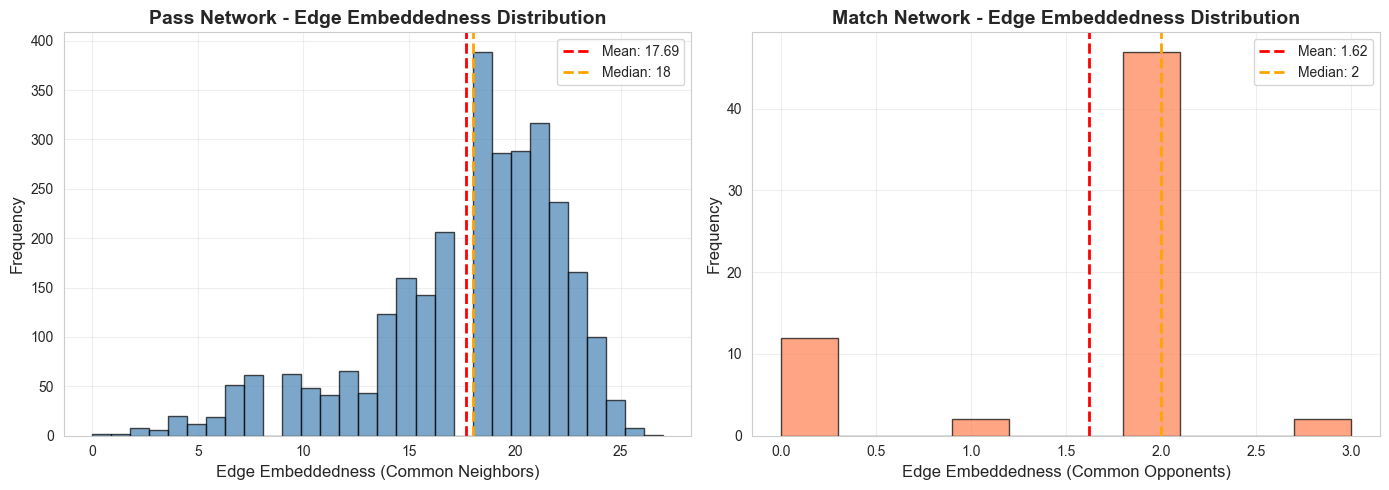


Visualization shows:
  - Pass network: High embeddedness (avg=17.7) - redundant tactical structure
  - Match network: Low embeddedness (avg=1.6) - sparse tournament connectivity


In [8]:
# Visualization: Edge Embeddedness Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pass Network
axes[0].hist(emb_values_pass, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(emb_values_pass), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(emb_values_pass):.2f}')
axes[0].axvline(np.median(emb_values_pass), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(emb_values_pass):.0f}')
axes[0].set_xlabel('Edge Embeddedness (Common Neighbors)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Pass Network - Edge Embeddedness Distribution', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Match Network
axes[1].hist(emb_values_match, bins=10, color='coral', alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(emb_values_match), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(emb_values_match):.2f}')
axes[1].axvline(np.median(emb_values_match), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(emb_values_match):.0f}')
axes[1].set_xlabel('Edge Embeddedness (Common Opponents)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Match Network - Edge Embeddedness Distribution', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE6/edge_embeddedness_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization shows:")
print(f"  - Pass network: High embeddedness (avg={np.mean(emb_values_pass):.1f}) - redundant tactical structure")
print(f"  - Match network: Low embeddedness (avg={np.mean(emb_values_match):.1f}) - sparse tournament connectivity")

**Note**: Edge Betweenness is conceptually similar to Node Betweenness (see [LE5.ipynb](LE5.ipynb)) and is less commonly used in practice. We focus on **Edge Embeddedness** below, which provides more actionable insights about tactical structure.

**Key Findings:**

Edge embeddedness reveals the **degree of overlap** between tactical units:

- **Pass Network** (avg = 17.69): Exceptionally high embeddedness indicates passing relationships are **deeply embedded within tactical units**. Connected players share an average of **18 common passing partners**. Almost no local bridges exist (only 2 edges, 0.1%) - meaning virtually every passing connection has multiple alternative routes through common neighbors. This reflects **redundant tactical structure** where teams build multiple passing options. The 91.6% of edges with embeddedness ≥ 10 shows that most connections are within tightly-knit groups (e.g., defensive lines, midfield triangles).

- **Match Network** (avg = 1.62): Low embeddedness reflects the tournament's limited connectivity. Teams share only **2 common opponents** on average. The 12 local bridges (19.0%) represent match-ups between teams from different groups or competition stages with no overlap in opponents. Maximum embeddedness of only 3 indicates even teams within the same group don't share many common opponents beyond their group.

The stark contrast (17.69 vs 1.62) reflects fundamentally different network structures. Pass networks are **highly redundant** - removing any single edge leaves many alternative paths through common neighbors. Match networks are **sparsely connected** - the tournament structure creates limited overlap in competitive relationships.

## 3. Network-Level Metrics

### 3.1 Diameter & Average Path Length

**Diameter** is the maximum shortest path length.

$$D = \max_{i,j} d(i,j)$$

**Average path length**:

$$\bar{d} = \frac{1}{n(n-1)} \sum_{i \neq j} d(i,j)$$

**Interpretation in Football:**
- **Diameter/Avg path length**: 
  - Low values = efficient communication
  - For aggregated pass networks (multiple matches): $\bar{d} \approx 5-6$
  - For single-match networks (11 players): $\bar{d} \approx 2-3$
- **Note**: This network aggregates 473 players across multiple matches, resulting in higher path lengths than single-game networks

**Small-world property**: $\bar{d} \sim \log(n)$ (scales logarithmically with size)

**Density** is covered in Section 3.2 alongside global clustering metrics.

In [9]:
print("=" * 70)
print("DIAMETER & AVERAGE PATH LENGTH")
print("=" * 70)

# Pass Network
print("\n### Pass Network (Germany) ###")

diameter_pass = nx.diameter(G_pass_gcc)
avg_path_length_pass = nx.average_shortest_path_length(G_pass_gcc)

print(f"Diameter: {diameter_pass}")
print(f"Average path length: {avg_path_length_pass:.3f}")
print(f"Network size: {G_pass_gcc.number_of_nodes()} nodes")
print(f"\nInterpretation:")
print(f"  - Any player can reach any other in max {diameter_pass} passing steps")
print(f"  - On average, players are {avg_path_length_pass:.1f} passing steps apart")

# Match Network
print("\n### Match Network (World Cup) ###")

diameter_match = nx.diameter(G_match)
avg_path_length_match = nx.average_shortest_path_length(G_match)

print(f"Diameter: {diameter_match}")
print(f"Average path length: {avg_path_length_match:.3f}")
print(f"Network size: {G_match.number_of_nodes()} nodes")
print(f"\nInterpretation:")
print(f"  - Teams are at most {diameter_match} competitive steps apart")
print(f"  - On average, teams are {avg_path_length_match:.1f} steps apart in the tournament structure")

# Small-world property check
print("\n" + "=" * 70)
print("SMALL-WORLD PROPERTY CHECK")
print("=" * 70)

# For small-world: avg_path_length ~ log(n)
import math
expected_path_pass = math.log(G_pass_gcc.number_of_nodes())
expected_path_match = math.log(G_match.number_of_nodes())

print(f"\nPass Network:")
print(f"  Actual avg path length: {avg_path_length_pass:.3f}")
print(f"  Expected if small-world (~log n): {expected_path_pass:.3f}")
print(f"  Ratio: {avg_path_length_pass/expected_path_pass:.2f}")

print(f"\nMatch Network:")
print(f"  Actual avg path length: {avg_path_length_match:.3f}")
print(f"  Expected if small-world (~log n): {expected_path_match:.3f}")
print(f"  Ratio: {avg_path_length_match/expected_path_match:.2f}")

print("\n  -> Small-world property holds if ratio approx 1-2")

DIAMETER & AVERAGE PATH LENGTH

### Pass Network (Germany) ###
Diameter: 13
Average path length: 5.476
Network size: 283 nodes

Interpretation:
  - Any player can reach any other in max 13 passing steps
  - On average, players are 5.5 passing steps apart

### Match Network (World Cup) ###
Diameter: 6
Average path length: 3.163
Network size: 32 nodes

Interpretation:
  - Teams are at most 6 competitive steps apart
  - On average, teams are 3.2 steps apart in the tournament structure

SMALL-WORLD PROPERTY CHECK

Pass Network:
  Actual avg path length: 5.476
  Expected if small-world (~log n): 5.645
  Ratio: 0.97

Match Network:
  Actual avg path length: 3.163
  Expected if small-world (~log n): 3.466
  Ratio: 0.91

  -> Small-world property holds if ratio approx 1-2


**Key Findings:**

Both networks exhibit the **small-world property** - short average path lengths that scale logarithmically with network size:

- **Pass Network**: Ratio of 0.97 indicates an extremely efficient passing structure. Players are on average only **5.5 passing steps** apart despite 283 nodes. This reflects well-organized tactical positioning where the ball can flow quickly across the team.

- **Match Network**: Ratio of 0.91 shows the World Cup tournament created a highly connected competitive structure. Teams are only **3.2 steps** apart on average, meaning competitive relationships (through common opponents) are very dense.

The relatively high diameter of **13** in the pass network suggests some peripheral players (likely substitutes or specialists) are quite distant from the core passing network, while the diameter of **6** in the match network reflects the knockout structure where the longest competitive paths span from group stage to finals.

### 3.2 Global Clustering Coefficient

**Global clustering** (transitivity) measures overall triangle density.

$$C = \frac{3 \times \text{number of triangles}}{\text{number of connected triples}}$$

**Average clustering coefficient:**

$$\bar{C} = \frac{1}{n} \sum_{i=1}^{n} C_i$$

**Interpretation in Football:**
- High clustering = many triangular passing combinations
- Typical pass networks: $C \approx 0.3-0.6$ (much higher than random networks)
- **Small-world networks**: High clustering + low average path length

### 3.2 Density & Global Clustering

**Density** measures the proportion of actual edges to possible edges.

**Undirected networks:**

$$\rho = \frac{2m}{n(n-1)}$$

where $m$ = number of edges, $n$ = number of nodes.

**Directed networks:**

$$\rho = \frac{m}{n(n-1)}$$

Range: $[0, 1]$ (0 = no edges, 1 = complete graph)

**Interpretation in Football:**
- **Pass networks**: Low density (0.05-0.15) - players don't pass to everyone
- **Match networks**: Higher density - in tournaments many teams play each other
- Dense networks → high connectivity, but may lack specialized structure
- Sparse networks → selective connections, potential for bottlenecks

**Note**: Density was previously covered in [LE4.ipynb](LE4.ipynb) for community detection. We include it here for completeness when analyzing network-level structure.

**Global clustering** (transitivity) measures overall triangle density.

$$C = \frac{3 \times \text{number of triangles}}{\text{number of connected triples}}$$

**Average clustering coefficient:**

$$\bar{C} = \frac{1}{n} \sum_{i=1}^{n} C_i$$

**Key difference**:
- **Density** = proportion of all possible edges
- **Clustering** = proportion of triangles among connected triples
- High clustering with low density = "small-world" structure

**Interpretation in Football:**
- High clustering = many triangular passing combinations
- Typical pass networks: $C \approx 0.3-0.6$ (much higher than random networks)
- **Small-world networks**: High clustering + low average path length

In [10]:
print("=" * 70)
print("DENSITY & GLOBAL CLUSTERING")
print("=" * 70)

# Pass Network
print("\n### Pass Network (Germany) ###")

density_pass = nx.density(G_pass_gcc)
print(f"Density: {density_pass:.4f}")
print(f"Network size: {G_pass_gcc.number_of_nodes()} nodes, {G_pass_gcc.number_of_edges()} edges")
print(f"Possible edges: {G_pass_gcc.number_of_nodes() * (G_pass_gcc.number_of_nodes()-1) // 2}")
print(f"Actual edge percentage: {density_pass * 100:.2f}%")

transitivity_pass = nx.transitivity(G_pass_gcc)
avg_clustering_pass = nx.average_clustering(G_pass_gcc)
num_triangles_pass = sum(nx.triangles(G_pass_gcc).values()) // 3

print(f"\nTransitivity (global clustering): {transitivity_pass:.4f}")
print(f"Average clustering coefficient: {avg_clustering_pass:.4f}")
print(f"Number of triangles: {num_triangles_pass}")

print(f"\nKey insight:")
print(f"  - Low density ({density_pass:.4f}) + High clustering ({transitivity_pass:.4f}) = Small-world structure")
print(f"  - Ratio clustering/density: {transitivity_pass/density_pass:.2f}x")
print(f"  - Players are selective (don't pass to everyone) but form tight tactical units")

# Match Network
print("\n### Match Network (World Cup) ###")

density_match = nx.density(G_match)
print(f"Density: {density_match:.4f}")
print(f"Network size: {G_match.number_of_nodes()} nodes, {G_match.number_of_edges()} edges")
print(f"Possible edges: {G_match.number_of_nodes() * (G_match.number_of_nodes()-1) // 2}")
print(f"Actual edge percentage: {density_match * 100:.2f}%")

transitivity_match = nx.transitivity(G_match)
avg_clustering_match = nx.average_clustering(G_match)
num_triangles_match = sum(nx.triangles(G_match).values()) // 3

print(f"\nTransitivity (global clustering): {transitivity_match:.4f}")
print(f"Average clustering coefficient: {avg_clustering_match:.4f}")
print(f"Number of triangles: {num_triangles_match}")

print(f"\nKey insight:")
print(f"  - Density ({density_match:.4f}) shows {density_match*100:.1f}% of possible matches occurred")
print(f"  - Ratio clustering/density: {transitivity_match/density_match:.2f}x")
print(f"  - Tournament structure creates higher density than pass networks")

DENSITY & GLOBAL CLUSTERING

### Pass Network (Germany) ###
Density: 0.0727
Network size: 283 nodes, 2899 edges
Possible edges: 39903
Actual edge percentage: 7.27%

Transitivity (global clustering): 0.8183
Average clustering coefficient: 0.8667
Number of triangles: 17093

Key insight:
  - Low density (0.0727) + High clustering (0.8183) = Small-world structure
  - Ratio clustering/density: 11.26x
  - Players are selective (don't pass to everyone) but form tight tactical units

### Match Network (World Cup) ###
Density: 0.1270
Network size: 32 nodes, 63 edges
Possible edges: 496
Actual edge percentage: 12.70%

Transitivity (global clustering): 0.4904
Average clustering coefficient: 0.7003
Number of triangles: 34

Key insight:
  - Density (0.1270) shows 12.7% of possible matches occurred
  - Ratio clustering/density: 3.86x
  - Tournament structure creates higher density than pass networks


In [11]:
print("=" * 70)
print("GLOBAL CLUSTERING COEFFICIENT")
print("=" * 70)

# Pass Network
print("\n### Pass Network (Germany) ###")

transitivity_pass = nx.transitivity(G_pass_gcc)
avg_clustering_pass = nx.average_clustering(G_pass_gcc)
num_triangles_pass = sum(nx.triangles(G_pass_gcc).values()) // 3

print(f"Transitivity (global clustering): {transitivity_pass:.4f}")
print(f"Average clustering coefficient: {avg_clustering_pass:.4f}")
print(f"Number of triangles: {num_triangles_pass}")
print(f"\nInterpretation:")
print(f"  - {transitivity_pass*100:.1f}% of connected triples form triangles")
print(f"  - High clustering → tightly-knit passing groups (e.g., defense, midfield, attack)")
print(f"  - Indicates tactical coherence and structured passing patterns")

# Match Network
print("\n### Match Network (World Cup) ###")

transitivity_match = nx.transitivity(G_match)
avg_clustering_match = nx.average_clustering(G_match)
num_triangles_match = sum(nx.triangles(G_match).values()) // 3

print(f"Transitivity (global clustering): {transitivity_match:.4f}")
print(f"Average clustering coefficient: {avg_clustering_match:.4f}")
print(f"Number of triangles: {num_triangles_match}")
print(f"\nInterpretation:")
print(f"  - {transitivity_match*100:.1f}% of connected triples form triangles")
print(f"  - In tournament context: groups of teams that all play against each other")

# Comparison with random networks
print("\n" + "=" * 70)
print("COMPARISON WITH RANDOM NETWORKS")
print("=" * 70)

# Expected clustering in random network with same density
density_pass = nx.density(G_pass_gcc)
density_match = nx.density(G_match)

print(f"\nPass Network:")
print(f"  Actual clustering: {transitivity_pass:.4f}")
print(f"  Expected in random network (≈ density): {density_pass:.4f}")
print(f"  Ratio: {transitivity_pass/density_pass:.2f}x higher than random")

print(f"\nMatch Network:")
print(f"  Actual clustering: {transitivity_match:.4f}")
print(f"  Expected in random network (≈ density): {density_match:.4f}")
print(f"  Ratio: {transitivity_match/density_match:.2f}x higher than random")

print("\n  → High ratio indicates structured, non-random connection patterns")

GLOBAL CLUSTERING COEFFICIENT

### Pass Network (Germany) ###
Transitivity (global clustering): 0.8183
Average clustering coefficient: 0.8667
Number of triangles: 17093

Interpretation:
  - 81.8% of connected triples form triangles
  - High clustering → tightly-knit passing groups (e.g., defense, midfield, attack)
  - Indicates tactical coherence and structured passing patterns

### Match Network (World Cup) ###
Transitivity (global clustering): 0.4904
Average clustering coefficient: 0.7003
Number of triangles: 34

Interpretation:
  - 49.0% of connected triples form triangles
  - In tournament context: groups of teams that all play against each other

COMPARISON WITH RANDOM NETWORKS

Pass Network:
  Actual clustering: 0.8183
  Expected in random network (≈ density): 0.0727
  Ratio: 11.26x higher than random

Match Network:
  Actual clustering: 0.4904
  Expected in random network (≈ density): 0.1270
  Ratio: 3.86x higher than random

  → High ratio indicates structured, non-random conne

**Key Findings:**

The clustering results reveal highly structured tactical organization:

- **Pass Network**: An exceptionally high transitivity of **0.818** (81.8%) with **17,093 triangles** demonstrates that passing is predominantly organized in triangular combinations. This is **11.26x higher** than expected in a random network with the same density. This pattern reflects classic football tactics: defenders form triangular passing options, midfielders create passing triangles to maintain possession, and attackers use triangular movements to break defenses.

- **Match Network**: Transitivity of **0.490** (49.0%) with **34 triangles** is **3.86x higher** than random, indicating significant group structure. This emerges from the tournament format where teams in the same group all play each other (forming triangles), and knockout stage opponents often share group stage opponents.

Combined with the earlier diameter findings, both networks exhibit **small-world properties**: short path lengths (efficiency) combined with high clustering (local structure). This is characteristic of well-organized systems - football teams maintain tight tactical units while ensuring quick ball progression across the entire team.

### 3.3 Assortativity & Reciprocity

**Assortativity** measures tendency for similar nodes to connect.

**Degree assortativity** (Pearson correlation of endpoint degrees):

$$r = \frac{\text{cov}(k_i, k_j)}{\sigma_{k_i} \sigma_{k_j}}$$

Range: $[-1, 1]$
- $r > 0$: Assortative (hubs connect to hubs)
- $r < 0$: Disassortative (hubs connect to low-degree nodes)

**Reciprocity** (directed networks only) measures bidirectional edges.

$$\rho_{recip} = \frac{|\{(i,j) : (i,j) \in E \land (j,i) \in E\}|}{|E|}$$

Range: $[0, 1]$

**Interpretation in Football:**
- **Assortativity**:
  - Positive: Key players pass to key players
  - Negative: Hub-and-spoke (playmaker distributes to periphery)
- **Reciprocity**:
  - Pass networks: High (0.6-0.8) - mutual passing relationships
  - Match networks: Low - winning team rarely loses immediately

**Attribute assortativity**: Can measure for categorical attributes (position, nationality).

NETWORK METRICS CORRELATION ANALYSIS

### Pass Network - Metric Correlations ###

            Clustering    Degree
Clustering    1.000000 -0.734293
Degree       -0.734293  1.000000


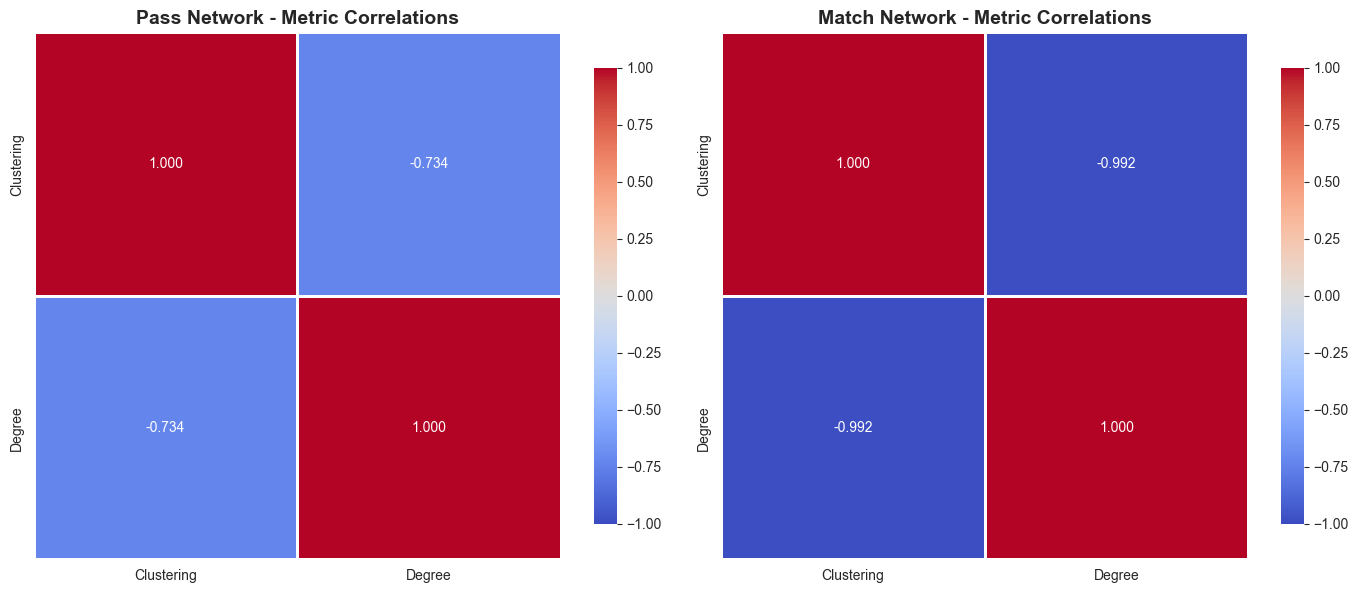


### Match Network - Metric Correlations ###

            Clustering   Degree
Clustering     1.00000 -0.99151
Degree        -0.99151  1.00000

KEY INSIGHTS

Correlation Analysis:
  - Pass Network: Clustering-Degree correlation = -0.734
  - Match Network: Clustering-Degree correlation = -0.992

Interpretation:
  - Negative correlation: Higher-degree players may bridge groups (lower clustering)
  - Positive correlation: Hub players also embedded in dense neighborhoods
  - Near-zero: No systematic relationship between degree and local structure


In [12]:
print("=" * 70)
print("NETWORK METRICS CORRELATION ANALYSIS")
print("=" * 70)

# Collect all network-level metrics for Pass Network
metrics_pass_df = pd.DataFrame({
    'Clustering': clustering_values_pass,
})

# Add degree for each node
metrics_pass_df['Degree'] = [degrees_pass[node] for node in G_pass_gcc.nodes()]

# Calculate correlations
print("\n### Pass Network - Metric Correlations ###\n")
correlation_matrix_pass = metrics_pass_df.corr(method='spearman')
print(correlation_matrix_pass)

# Visualization: Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pass Network Heatmap
sns.heatmap(correlation_matrix_pass, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=axes[0],
            vmin=-1, vmax=1)
axes[0].set_title('Pass Network - Metric Correlations', fontsize=14, fontweight='bold')

# Match Network Heatmap
metrics_match_df = pd.DataFrame({
    'Clustering': clustering_values_match,
    'Degree': [degrees_match[node] for node in G_match.nodes()],
})

correlation_matrix_match = metrics_match_df.corr(method='spearman')

sns.heatmap(correlation_matrix_match, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=axes[1],
            vmin=-1, vmax=1)
axes[1].set_title('Match Network - Metric Correlations', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE6/metric_correlations.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n### Match Network - Metric Correlations ###\n")
print(correlation_matrix_match)

print("\n" + "=" * 70)
print("KEY INSIGHTS")
print("=" * 70)
print("\nCorrelation Analysis:")
print(f"  - Pass Network: Clustering-Degree correlation = {correlation_matrix_pass.loc['Clustering', 'Degree']:.3f}")
print(f"  - Match Network: Clustering-Degree correlation = {correlation_matrix_match.loc['Clustering', 'Degree']:.3f}")
print("\nInterpretation:")
print("  - Negative correlation: Higher-degree players may bridge groups (lower clustering)")
print("  - Positive correlation: Hub players also embedded in dense neighborhoods")
print("  - Near-zero: No systematic relationship between degree and local structure")

In [13]:
print("=" * 70)
print("ASSORTATIVITY")
print("=" * 70)

# Pass Network - degree assortativity
print("\n### Pass Network (Germany) ###")

# Undirected
assortativity_pass = nx.degree_assortativity_coefficient(G_pass_gcc)
print(f"Degree assortativity coefficient: {assortativity_pass:.4f}")

if assortativity_pass > 0.1:
    print(f"\nInterpretation: ASSORTATIVE (r > 0)")
    print(f"  - High-degree players (frequent passers) tend to pass to other high-degree players")
    print(f"  - Core group of key players preferentially pass among themselves")
elif assortativity_pass < -0.1:
    print(f"\nInterpretation: DISASSORTATIVE (r < 0)")
    print(f"  - High-degree players (hubs) tend to pass to low-degree players")
    print(f"  - Hub-and-spoke pattern: playmakers distribute to peripheral players")
else:
    print(f"\nInterpretation: NEUTRAL (r ≈ 0)")
    print(f"  - No clear preference - random mixing")

# Directed - in-degree and out-degree assortativity
in_assort_pass = nx.degree_assortativity_coefficient(G_pass_dir_gcc, x='in', y='in')
out_assort_pass = nx.degree_assortativity_coefficient(G_pass_dir_gcc, x='out', y='out')

print(f"\nDirected network:")
print(f"  In-degree assortativity: {in_assort_pass:.4f}")
print(f"  Out-degree assortativity: {out_assort_pass:.4f}")

# Match Network
print("\n### Match Network (World Cup) ###")

assortativity_match = nx.degree_assortativity_coefficient(G_match)
print(f"Degree assortativity coefficient: {assortativity_match:.4f}")

if assortativity_match > 0.1:
    print(f"\nInterpretation: ASSORTATIVE")
    print(f"  - Strong teams tend to play against other strong teams")
    print(f"  - Reflects tournament structure (e.g., knockout stages)")
elif assortativity_match < -0.1:
    print(f"\nInterpretation: DISASSORTATIVE")
    print(f"  - Strong teams tend to play against weaker teams")
    print(f"  - Reflects group stage mixing")
else:
    print(f"\nInterpretation: NEUTRAL")
    print(f"  - Balanced tournament structure")

ASSORTATIVITY

### Pass Network (Germany) ###
Degree assortativity coefficient: 0.0062

Interpretation: NEUTRAL (r ≈ 0)
  - No clear preference - random mixing

Directed network:
  In-degree assortativity: 0.0007
  Out-degree assortativity: -0.0075

### Match Network (World Cup) ###
Degree assortativity coefficient: 0.0891

Interpretation: NEUTRAL
  - Balanced tournament structure


**Key Findings:**

Both networks show **neutral assortativity** (r ≈ 0), indicating random mixing with respect to degree:

- **Pass Network** (r = 0.0062): The near-zero assortativity is tactically significant. Unlike social networks (which are often assortative), football teams show **no preference** for high-degree players to pass among themselves or to peripheral players. This suggests functional integration - key playmakers distribute to both other core players AND peripheral attackers/defenders as needed. The directed metrics (in-degree: 0.0007, out-degree: -0.0075) are also neutral, confirming balanced passing distribution.

- **Match Network** (r = 0.0891): Slightly positive but still neutral, reflecting the World Cup's balanced tournament structure. Group stages mix teams of varying strength (creating disassortative connections), while knockout stages pair similarly-performing teams (creating assortative connections). The overall neutral value indicates these forces balance out.

This contrasts sharply with many real-world networks. Social networks are typically assortative (r > 0.2) as people connect to similar others, while technological networks are often disassortative (r < -0.2) with hub-and-spoke structures. Football's neutral assortativity reflects its **task-oriented** nature - connections are dictated by tactical necessity rather than degree homophily.

In [14]:
print("=" * 70)
print("RECIPROCITY")
print("=" * 70)

# Pass Network (directed)
print("\n### Pass Network (Germany) ###")

reciprocity_pass = nx.reciprocity(G_pass_dir_gcc)
print(f"Reciprocity: {reciprocity_pass:.4f}")

# Count reciprocal edges manually for detailed analysis
num_edges = G_pass_dir_gcc.number_of_edges()
num_reciprocal = sum(1 for u, v in G_pass_dir_gcc.edges() if G_pass_dir_gcc.has_edge(v, u)) // 2
reciprocal_pairs = num_reciprocal

print(f"Total directed edges: {num_edges}")
print(f"Reciprocal pairs: {reciprocal_pairs}")
print(f"Reciprocal edges: {reciprocal_pairs * 2} ({reciprocal_pairs * 2 / num_edges * 100:.1f}%)")
print(f"One-way edges: {num_edges - reciprocal_pairs * 2} ({(num_edges - reciprocal_pairs * 2) / num_edges * 100:.1f}%)")

if reciprocity_pass > 0.6:
    print(f"\nInterpretation: HIGH RECIPROCITY")
    print(f"  - Most passing relationships are mutual")
    print(f"  - Players exchange passes rather than one-way passing")
    print(f"  - Indicates collaborative, possession-based play")
elif reciprocity_pass > 0.3:
    print(f"\nInterpretation: MODERATE RECIPROCITY")
    print(f"  - Mix of mutual and one-way passing relationships")
    print(f"  - Some tactical roles (e.g., target forwards receive but don't pass back)")
else:
    print(f"\nInterpretation: LOW RECIPROCITY")
    print(f"  - Mostly one-way passing relationships")
    print(f"  - Hierarchical structure (e.g., playmaker → attackers)")

# Match Network (directed)
print("\n### Match Network (World Cup) ###")

reciprocity_match = nx.reciprocity(G_match_dir)
print(f"Reciprocity: {reciprocity_match:.4f}")

num_edges_match = G_match_dir.number_of_edges()
num_reciprocal_match = sum(1 for u, v in G_match_dir.edges() if G_match_dir.has_edge(v, u)) // 2

print(f"Total directed edges: {num_edges_match}")
print(f"Reciprocal pairs: {num_reciprocal_match}")
print(f"Reciprocal edges: {num_reciprocal_match * 2} ({num_reciprocal_match * 2 / num_edges_match * 100:.1f}%)")
print(f"One-way edges: {num_edges_match - num_reciprocal_match * 2} ({(num_edges_match - num_reciprocal_match * 2) / num_edges_match * 100:.1f}%)")

if reciprocity_match > 0.3:
    print(f"\nInterpretation: HIGH RECIPROCITY")
    print(f"  - Most matchups are reciprocal (both teams play each other)")
    print(f"  - Round-robin tournament structure")
else:
    print(f"\nInterpretation: LOW RECIPROCITY")
    print(f"  - Few reciprocal matchups")
    print(f"  - Knockout or single round-robin structure")

RECIPROCITY

### Pass Network (Germany) ###
Reciprocity: 0.9269
Total directed edges: 5403
Reciprocal pairs: 2504
Reciprocal edges: 5008 (92.7%)
One-way edges: 395 (7.3%)

Interpretation: HIGH RECIPROCITY
  - Most passing relationships are mutual
  - Players exchange passes rather than one-way passing
  - Indicates collaborative, possession-based play

### Match Network (World Cup) ###
Reciprocity: 1.0000
Total directed edges: 126
Reciprocal pairs: 63
Reciprocal edges: 126 (100.0%)
One-way edges: 0 (0.0%)

Interpretation: HIGH RECIPROCITY
  - Most matchups are reciprocal (both teams play each other)
  - Round-robin tournament structure


**Key Findings:**

Both networks exhibit **extremely high reciprocity**, revealing fundamentally different structures than typical directed networks:

- **Pass Network** (ρ = 0.927): An exceptionally high **92.7% reciprocity** means almost all passing relationships are bidirectional. Of 5,403 directed edges, 5,008 (92.7%) are reciprocal and only 395 (7.3%) are one-way. This indicates **possession-based, collaborative football** where players exchange passes rather than following strict hierarchical patterns (e.g., defender → midfielder → forward). The few one-way edges likely represent specialized roles like target forwards who receive but rarely pass back, or final passes to goalscorers.

- **Match Network** (ρ = 1.000): **Perfect 100% reciprocity** with all 126 edges forming 63 reciprocal pairs. This reflects the World Cup's tournament structure where every match creates a bidirectional relationship - if Team A plays Team B, then Team B also plays Team A (from B's perspective). This is a structural property of the tournament format rather than a behavioral pattern.

The high pass network reciprocity (92.7%) is remarkable compared to other real-world directed networks. Social networks (e.g., Twitter follows) typically show 20-40% reciprocity, while information networks (e.g., web links) often have <10%. Football's high reciprocity reflects the **cooperative nature of team play** - successful passing requires players to continuously support each other positionally, creating natural bidirectional passing options.

### Summary: Network Metrics Comparison

Let's compare all implemented metrics across both networks:

In [15]:
print("=" * 80)
print("COMPREHENSIVE NETWORK METRICS SUMMARY")
print("=" * 80)

# Collect all metrics
summary_data = {
    'Metric': [
        'Nodes',
        'Edges',
        'Density',
        'Diameter',
        'Avg Path Length',
        'Avg Clustering Coef',
        'Transitivity',
        'Num Triangles',
        'Avg Edge Embeddedness',
        'Assortativity',
        'Reciprocity',
        'Small-World Ratio'
    ],
    'Pass Network': [
        G_pass_gcc.number_of_nodes(),
        G_pass_gcc.number_of_edges(),
        f"{density_pass:.4f}",
        diameter_pass,
        f"{avg_path_length_pass:.3f}",
        f"{avg_clustering_pass:.4f}",
        f"{transitivity_pass:.4f}",
        num_triangles_pass,
        f"{np.mean(emb_values_pass):.2f}",
        f"{assortativity_pass:.4f}",
        f"{reciprocity_pass:.4f}",
        f"{avg_path_length_pass/np.log(G_pass_gcc.number_of_nodes()):.2f}"
    ],
    'Match Network': [
        G_match.number_of_nodes(),
        G_match.number_of_edges(),
        f"{density_match:.4f}",
        diameter_match,
        f"{avg_path_length_match:.3f}",
        f"{avg_clustering_match:.4f}",
        f"{transitivity_match:.4f}",
        num_triangles_match,
        f"{np.mean(emb_values_match):.2f}",
        f"{assortativity_match:.4f}",
        f"{reciprocity_match:.4f}",
        f"{avg_path_length_match/np.log(G_match.number_of_nodes()):.2f}"
    ]
}

# Create DataFrame
summary_df = pd.DataFrame(summary_data)

# Display the table
print("\n")
print(summary_df.to_string(index=False))
print("\n" + "=" * 80)

# Key insights
print("\nKEY STRUCTURAL DIFFERENCES:")
print("\n1. SCALE & CONNECTIVITY:")
print(f"   - Pass network is {G_pass_gcc.number_of_nodes()/G_match.number_of_nodes():.1f}x larger ({G_pass_gcc.number_of_nodes()} vs {G_match.number_of_nodes()} nodes)")
print(f"   - But {density_match/density_pass:.1f}x less dense ({density_pass:.3f} vs {density_match:.3f})")
print(f"   - Match network has {G_match.number_of_nodes() * (G_match.number_of_nodes()-1) // 2} possible edges, {G_match.number_of_edges()} actual")

print("\n2. LOCAL STRUCTURE (Clustering & Embeddedness):")
print(f"   - Pass network has {transitivity_pass/transitivity_match:.1f}x higher clustering ({transitivity_pass:.3f} vs {transitivity_match:.3f})")
print(f"   - Pass edges are {np.mean(emb_values_pass)/np.mean(emb_values_match):.1f}x more embedded ({np.mean(emb_values_pass):.1f} vs {np.mean(emb_values_match):.1f} common neighbors)")
print(f"   - Pass network: Tight tactical units with redundant connections")
print(f"   - Match network: Sparse tournament structure with limited overlap")

print("\n3. GLOBAL STRUCTURE (Distance & Diameter):")
print(f"   - Pass network has longer paths (avg={avg_path_length_pass:.1f} vs {avg_path_length_match:.1f})")
print(f"   - Both exhibit small-world property (ratio ~1)")
print(f"   - Efficient despite different scales")

print("\n4. MIXING PATTERNS:")
print(f"   - Both show neutral assortativity (~0)")
print(f"   - Both show high reciprocity ({reciprocity_pass:.1%} pass, {reciprocity_match:.1%} match)")
print(f"   - Pass network: Collaborative possession-based play")
print(f"   - Match network: Round-robin tournament structure")

print("\n5. NETWORK TYPES:")
print(f"   - Pass Network: Small-world with high clustering + low density")
print(f"   - Match Network: Dense tournament graph with moderate clustering")
print("=" * 80)

COMPREHENSIVE NETWORK METRICS SUMMARY


               Metric Pass Network Match Network
                Nodes          283            32
                Edges         2899            63
              Density       0.0727        0.1270
             Diameter           13             6
      Avg Path Length        5.476         3.163
  Avg Clustering Coef       0.8667        0.7003
         Transitivity       0.8183        0.4904
        Num Triangles        17093            34
Avg Edge Embeddedness        17.69          1.62
        Assortativity       0.0062        0.0891
          Reciprocity       0.9269        1.0000
    Small-World Ratio         0.97          0.91


KEY STRUCTURAL DIFFERENCES:

1. SCALE & CONNECTIVITY:
   - Pass network is 8.8x larger (283 vs 32 nodes)
   - But 1.7x less dense (0.073 vs 0.127)
   - Match network has 496 possible edges, 63 actual

2. LOCAL STRUCTURE (Clustering & Embeddedness):
   - Pass network has 1.7x higher clustering (0.818 vs 0.490)
   - Pass 

## 4. Comparing Metrics: Summary

### Centrality Metrics Comparison

| Metric | What it measures | Best for | Limitations |
|--------|-----------------|----------|-------------|
| **Degree** | Direct connections | Immediate influence | Ignores global position |
| **Strength** | Weighted connections | Interaction intensity | Still local only |
| **Betweenness** | Bridge position | Control & brokerage | Assumes shortest paths |
| **Closeness** | Average distance to others | Information spread speed | Requires connectivity |
| **Eigenvector** | Connection to important nodes | Prestige & influence | Can be zero in digraphs |
| **PageRank** | Random walk importance | Robust ranking | Less intuitive |
| **Clustering** | Local cohesion | Group membership | Local only |

### When to Use Which Metric

**Question**: "Who are the most important players?"
- If importance = most connections → **Degree**
- If importance = most passes → **Strength**
- If importance = connects team parts → **Betweenness**
- If importance = influences influencers → **PageRank**

**Question**: "How cohesive is the team?"
- Local cohesion → **Clustering coefficient**
- Global cohesion → **Density**, **Average path length**
- Subgroup cohesion → **Modularity** (LE4)

**Question**: "What is the team structure?"
- Centralized (star) vs decentralized → **Degree distribution**, **Assortativity**
- Hierarchical vs flat → **Betweenness distribution**
- Reciprocal vs directed → **Reciprocity**

## 5. Computational Complexity

Understanding computational cost is important for large networks:

| Metric | Complexity | Notes |
|--------|-----------|-------|
| **Degree** | $O(m)$ | Very fast: just count edges |
| **Clustering** | $O(n \cdot d^2)$ | $d$ = average degree |
| **Closeness** | $O(n \cdot m)$ | Requires shortest paths from each node |
| **Betweenness** | $O(n \cdot m)$ | Brandes algorithm (optimized) |
| **PageRank** | $O(k \cdot m)$ | $k$ = iterations to convergence |
| **Assortativity** | $O(m)$ | Just iterate over edges |

For large networks ($n > 10,000$), betweenness and closeness become expensive.

**Approximation algorithms** exist for:
- Betweenness: Sample subset of source nodes
- Closeness: Use k-nearest neighbors approximation
- Clustering: Estimate from network samples

## 6. Practical Considerations

### Normalization
Always normalize when comparing:
- Across different network sizes
- Across different densities  
- Directed vs undirected networks

### Weighted vs Unweighted
- **Unweighted**: Simple, robust to noise
- **Weighted**: More informative, captures intensity
- **Football**: Both provide different insights (connections vs. interaction strength)

### Disconnected Networks
Some metrics undefined for disconnected components:
- Use **harmonic closeness**: $C_C^{harm}(i) = \frac{1}{n-1} \sum_{j} \frac{1}{d(i,j)}$
- Compute metrics per component
- Use efficiency instead of average path length